In [1]:
import numpy as np
import pandas as pd
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, fbeta_score, accuracy_score, ConfusionMatrixDisplay, make_scorer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import joblib


In [2]:
df = pd.read_parquet('../data/processed/abcd_first_msgs.parquet')
# df_sample = pd.read_json('../raw_data/abcd_sample.json')


In [3]:
df

,split,id,flow,subflow,first_msgs,refund,refund_label,n_words
0,train,3592,product_defect,return_size,"Hi! I need to return an item, can you help me ...",0,1,13
1,train,9489,product_defect,refund_status,just wanted to check on the status of a refund,0,0,10
2,train,3695,storewide_query,timing_4,HEY HO! I've got a promo code and I want to kn...,0,0,27
3,train,5798,shipping_issue,manage,"Hello, I would like to change my shipping deat...",0,1,18
4,train,3647,storewide_query,pricing_3,Hello. I have a really cool party coming up. A...,0,0,34
...,...,...,...,...,...,...,...,...
10037,test,1622,order_issue,manage_upgrade,HI I want to upgrade an order I have with you ...,0,0,14
10038,test,3293,manage_account,status_credit_missing,"Hi, I think I am missing a $40 credit from a s...",0,0,13
10039,test,8492,subscription_inquiry,manage_extension,I would like an extension on my subscription.,0,0,8
10040,test,189,storewide_query,pricing_1,Hi! How much do you charge to gift wrap items?,0,0,10


In [4]:


# stop_words = set(ENGLISH_STOP_WORDS) - {"no", "not", "nor", "never", "give", "back"}
def clean_message(text):
    if pd.isna(text):
        return ""

    text = str(text).lower().strip()

    text = text.replace("’", "'")

    text = text.replace("won't", "will not")
    text = text.replace("can't", "can not")
    text = text.replace("n't", " not")
    text = text.replace("you're", "you are")


    text = re.sub(r"\bho!", " ", text)

    text = re.sub(
        r"^(hi+|hello+|helo+|hey+|hiya|good morning|heyo|"
        r"good afternoon|good evening)\b[\s,.!]*",
        "", text
    )

    text = re.sub(r"[^\w\s]|_", " ", text)
    text = re.sub(r"\s+", " ", text).strip()


    # words = [word for word in text.split() if word not in stop_words]

    return text.strip()

df["clean_text"] = df["first_msgs"].apply(clean_message)

display(df[["first_msgs", "clean_text"]].head(10))

,first_msgs,clean_text
0,"Hi! I need to return an item, can you help me ...",i need to return an item can you help me with ...
1,just wanted to check on the status of a refund,just wanted to check on the status of a refund
2,HEY HO! I've got a promo code and I want to kn...,i ve got a promo code and i want to know when ...
3,"Hello, I would like to change my shipping deat...",i would like to change my shipping deatails as...
4,Hello. I have a really cool party coming up. A...,i have a really cool party coming up and i nee...
5,I want an extension for my shopping service. I...,i want an extension for my shopping service i ...
6,"Hello, I am trying to check the status of my o...",i am trying to check the status of my order bu...
7,Hello I am trying to buy a pair of boots but t...,i am trying to buy a pair of boots but they ar...
8,I accidently ordered the wrong item and was wo...,i accidently ordered the wrong item and was wo...
9,I would like to confirm my address is correct ...,i would like to confirm my address is correct ...


In [5]:
df

,split,id,flow,subflow,first_msgs,refund,refund_label,n_words,clean_text
0,train,3592,product_defect,return_size,"Hi! I need to return an item, can you help me ...",0,1,13,i need to return an item can you help me with ...
1,train,9489,product_defect,refund_status,just wanted to check on the status of a refund,0,0,10,just wanted to check on the status of a refund
2,train,3695,storewide_query,timing_4,HEY HO! I've got a promo code and I want to kn...,0,0,27,i ve got a promo code and i want to know when ...
3,train,5798,shipping_issue,manage,"Hello, I would like to change my shipping deat...",0,1,18,i would like to change my shipping deatails as...
4,train,3647,storewide_query,pricing_3,Hello. I have a really cool party coming up. A...,0,0,34,i have a really cool party coming up and i nee...
...,...,...,...,...,...,...,...,...,...
10037,test,1622,order_issue,manage_upgrade,HI I want to upgrade an order I have with you ...,0,0,14,i want to upgrade an order i have with you to ...
10038,test,3293,manage_account,status_credit_missing,"Hi, I think I am missing a $40 credit from a s...",0,0,13,i think i am missing a 40 credit from a subscr...
10039,test,8492,subscription_inquiry,manage_extension,I would like an extension on my subscription.,0,0,8,i would like an extension on my subscription
10040,test,189,storewide_query,pricing_1,Hi! How much do you charge to gift wrap items?,0,0,10,how much do you charge to gift wrap items


In [6]:
# REFUND_SUBFLOWS = {
#     "refund_initiate",
#     "return_size",
#     "return_color",
#     "return_stain",
#     "manage_dispute_bill",
#     "bad_price_competitor",
#     "status_mystery_fee",
#     "refund_update",
#     "manage_cancel",
# }

# df["refund_request"] = df["subflow"].isin(REFUND_SUBFLOWS).astype(int)
# print(df["refund_request"].value_counts())

In [7]:
TARGET = "refund_label"

train = df[df["split"] == "train"]
val = df[df["split"] == "dev"]
test = df[df["split"] == "test"]

X_train = train["first_msgs"]
y_train = train[TARGET]

X_val = val["first_msgs"]
y_val = val[TARGET]

X_test = test["first_msgs"]
y_test = test[TARGET]

train_dev = df[df["split"].isin(["train", "dev"])]
X_td = train_dev["first_msgs"]
y_td = train_dev[TARGET]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [8]:
print(y_train.value_counts(normalize=True))

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred = dummy.predict(X_val)

print("accuracy:", accuracy_score(y_val, y_pred))
print("precision:", precision_score(y_val, y_pred, zero_division=0))
print("recall:", recall_score(y_val, y_pred))

refund_label
0    0.776948
1    0.223052
Name: proportion, dtype: float64
accuracy: 0.7719123505976095
precision: 0.0
recall: 0.0


In [9]:
models = {
    "count + none": make_pipeline(
        CountVectorizer(preprocessor=clean_message),
        LogisticRegression(max_iter=1000),
    ),
    "count + none + ngrams": make_pipeline(
        CountVectorizer(preprocessor=clean_message, ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000),
    ),
    "count + balanced": make_pipeline(
        CountVectorizer(preprocessor=clean_message),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "tfidf + none": make_pipeline(
        TfidfVectorizer(preprocessor=clean_message),
        LogisticRegression(max_iter=1000),
    ),
    "tfidf + balanced": make_pipeline(
        TfidfVectorizer(preprocessor=clean_message),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "tfidf + balanced + ngrams": make_pipeline(
        TfidfVectorizer(preprocessor=clean_message, ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
}

In [10]:
# for name, pipe in models.items():
#     pipe.fit(X_train, y_train)
#     print(f"\n=== {name} ===")
#     print(classification_report(y_val, pipe.predict(X_val)))

In [11]:
# results = []

# for name, pipe in models.items():
#     pipe.fit(X_train, y_train)
#     y_pred = pipe.predict(X_val)

#     results.append({
#         "model": name,
#         "precision": precision_score(y_val, y_pred),
#         "recall": recall_score(y_val, y_pred),
#         "f1": f1_score(y_val, y_pred),
#         "f2_recall_weighs_more": fbeta_score(y_val, y_pred, beta=2),
#     })

# results_df = pd.DataFrame(results).sort_values("f2_recall_weighs_more", ascending=False)
# results_df


In [12]:
# best_name = results_df.iloc[0]["model"]
# best_model = models[best_name]

In [13]:
def plot_confusion(y_true, y_pred, title):
    """Confusion matrix with plain-language labels, counts and row percentages."""
    # Counts and row percentages (each row adds up to 100%)
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = confusion_matrix(y_true, y_pred, normalize="true")

    # Unpack the four cells: correct no, false alarm, missed, correct yes
    tn, fp, fn, tp = cm.ravel()
    tn_pct, fp_pct, fn_pct, tp_pct = cm_pct.ravel()

    # Text inside each cell, in the same layout as the grid
    labels = [
        [f"Correct: no refund intent\n{tn} ({tn_pct:.0%})", f"False alarm\n{fp} ({fp_pct:.0%})"],
        [f"Missed refund intent\n{fn} ({fn_pct:.0%})", f"Correct: refund intent\n{tp} ({tp_pct:.0%})"],
    ]

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm_pct,
        annot=labels,
        fmt="",
        cmap="Blues",
        vmin=0,
        vmax=1,
        cbar=False,
        xticklabels=["Predicted: no refund", "Predicted: refund"],
        yticklabels=["Actually: no refund", "Actually: refund"],
    )
    plt.title(title)
    plt.show()

In [14]:
f2_scorer = make_scorer(fbeta_score, beta=2)

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_td, y_td, cv=cv,
        scoring={"precision": "precision",
                 "recall": "recall",
                 "f2": f2_scorer}
    )
    cv_results.append({
        "model": name,
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f2": scores["test_f2"].mean(),
        "f2_std": scores["test_f2"].std(),
    })
cv_results_df = pd.DataFrame(cv_results).sort_values("f2", ascending=False)
cv_best_name = cv_results_df.iloc[0]["model"]
print("Best model (CV):", cv_best_name)

cv_results_df

Best model (CV): tfidf + balanced + ngrams


,model,precision,recall,f2,f2_std
5,tfidf + balanced + ngrams,0.857563,0.903023,0.893371,0.010561
4,tfidf + balanced,0.811391,0.900544,0.881046,0.007909
2,count + balanced,0.823363,0.896086,0.880244,0.006344
1,count + none + ngrams,0.942419,0.844143,0.862087,0.009776
0,count + none,0.929509,0.833754,0.851192,0.016992
3,tfidf + none,0.946727,0.770416,0.800179,0.012279


In [15]:
best_pipe = models[cv_best_name]

param_grid = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "tfidfvectorizer__min_df": [1, 2],
    "tfidfvectorizer__sublinear_tf": [True, False],


    "logisticregression__C": [0.1, 1.0, 10.0],
    "logisticregression__class_weight": [None, "balanced"],
}

grid_search = GridSearchCV(
    estimator=best_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring=f2_scorer,
    n_jobs=1,
    verbose=1,
    refit=True
)
grid_search.fit(X_td, y_td)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': [0.1, 1.0, ...], 'logisticregression__class_weight': [None, 'balanced'], 'tfidfvectorizer__min_df': [1, 2], 'tfidfvectorizer__ngram_range': [(1, ...), (1, ...)], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f...dict', beta=2)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.

In [16]:
print(f"Best accuracy score:{grid_search.best_score_:.4f}")
print("Best parameters configuration:")
for param, value in grid_search.best_params_.items():
    print(f"  {param}: {value}")

Best accuracy score:0.8959
Best parameters configuration:
  logisticregression__C: 1.0
  logisticregression__class_weight: balanced
  tfidfvectorizer__min_df: 2
  tfidfvectorizer__ngram_range: (1, 2)
  tfidfvectorizer__sublinear_tf: True


In [17]:
grid_search_model = grid_search.best_estimator_

td_probs = cross_val_predict(
    grid_search_model, X_td, y_td, cv=cv, method="predict_proba"
)[:, 1]

threshold_results = []

for threshold in [0.35, 0.40, 0.42, 0.44, 0.46, 0.48, 0.50, 0.55]:
    y_pred = (td_probs >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_td, y_pred),
        "recall": recall_score(y_td, y_pred),
        "f2": fbeta_score(y_td, y_pred, beta=2),
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,threshold,precision,recall,f2
0,0.35,0.719640,0.950025,0.892857
1,0.40,0.780538,0.932707,0.897705
2,0.42,0.800256,0.927759,0.899108
3,0.44,0.816506,0.920336,0.897510
4,0.46,0.833258,0.914894,0.897311
5,0.48,0.848289,0.907472,0.894983
6,0.50,0.866224,0.903513,0.895801
7,0.55,0.898288,0.882731,0.885799


In [18]:
FINAL_THRESHOLD = 0.44
final_model = grid_search.best_estimator_


In [19]:
final_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",<function cle...t 0x11acf4fe0>
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'


precision: 0.7837837837837838
recall: 0.9269406392694064
f2: 0.8942731277533039


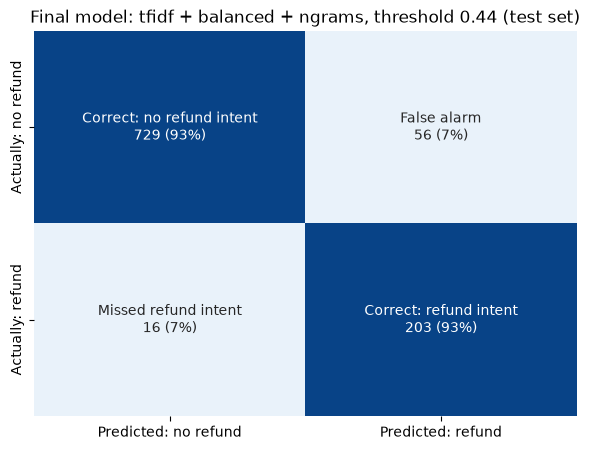

In [20]:

test_probs = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (test_probs >= FINAL_THRESHOLD).astype(int)

print("precision:", precision_score(y_test, y_pred_test))
print("recall:", recall_score(y_test, y_pred_test))
print("f2:", fbeta_score(y_test, y_pred_test, beta=2))

plot_confusion(
    y_test,
    y_pred_test,
    f"Final model: {cv_best_name}, threshold {FINAL_THRESHOLD} (test set)",
)

In [21]:
joblib.dump(final_model, "../models/tfidf_balanced_ngrams.joblib")

['../models/tfidf_balanced_ngrams.joblib']

In [22]:
prompts = [
    "I just want to talk to someone today",
    "hi! my jeans are too small, I want my money back",
    "where is my refund?",
    "can I change my delivery address?",
    "I bought some jeans but they dont fit",

]

for prompt in prompts:
    refund_prob = final_model.predict_proba([prompt])[0][1]
    print(f"Refund Intent: {refund_prob:.0%}  {prompt}")

Refund Intent: 26%  I just want to talk to someone today
Refund Intent: 44%  hi! my jeans are too small, I want my money back
Refund Intent: 87%  where is my refund?
Refund Intent: 41%  can I change my delivery address?
Refund Intent: 63%  I bought some jeans but they dont fit


In [23]:
# #check weights of words
# prompt_99 = "Hello! I bought these jeans. I want to return them for a different size and color."

# prompt = "I just want to talk to someone today"
# refund_prob = best_model.predict_proba([prompt])[0][1]
# print(f"Refund intent: {refund_prob:.0%}")

In [24]:
prompt_text = 'I recently purchased a skirt, but I realized I dont really wear those. I want my money back.'
test = clean_message(prompt_text)

print(test)

i recently purchased a skirt but i realized i dont really wear those i want my money back
